# MultiFC DA-MiniLM++: Temporal Robustness with Lightweight Sentence Embeddings

This notebook adapts the latest **DA-MiniLM++** model from the LIAR2 notebook to the **MultiFC** dataset.

Main design:

1. Use the previous MultiFC notebook only for **data loading and label harmonization**.
2. Use the latest DA-MiniLM++ pipeline as the main model:
   - frozen MiniLM embeddings,
   - class-balanced weighting,
   - recency-weighted training,
   - validation-selected temporal decay,
   - validation-based class-bias correction,
   - temperature calibration,
   - multi-seed robustness,
   - paired bootstrap and Benjamini-Hochberg correction.
3. Keep the official `dev.tsv` as a true held-out evaluation set in the official train→dev protocol.
4. Exclude evidence text and fact-check article title by default to reduce leakage risk.

Recommended paper framing: **external robustness check on MultiFC**, not a direct SOTA leaderboard comparison.

In [4]:
# ============================================================
# 0. Install dependencies if needed
# ============================================================
import sys, subprocess, importlib

required_packages = {
    "sentence_transformers": "sentence-transformers",
    "torch": "torch",
    "sklearn": "scikit-learn",
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
}

for import_name, pip_name in required_packages.items():
    try:
        importlib.import_module(import_name)
    except Exception:
        print(f"Installing {pip_name}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

In [5]:
# ============================================================
# 1. Imports and global configuration
# ============================================================
import os, re, json, math, random, warnings, shutil
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sentence_transformers import SentenceTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, classification_report, log_loss
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize

warnings.filterwarnings("ignore")

# -----------------------------
# Experiment switches
# -----------------------------
RUN_DA_MINILM_PLUS = True
RUN_LOGREG_BASELINE = True
RUN_ROLLING_WINDOWS = True
RUN_OFFICIAL_TEST_PREDICTIONS = True

# Keep title/evidence disabled by default to reduce leakage.
TEXT_MODES = ["claim_only", "claim_plus_safe_metadata"]
EVAL_SETUPS = ["official_train_to_dev", "internal_chronological", "internal_random_stratified"]

SEEDS = [42, 43, 44, 45, 46]
RECENCY_LAMBDAS = [0.00, 0.05, 0.10, 0.20, 0.30]
TAU_GRID = [0.0, 0.5, 1.0, 1.5, 2.0]
TEMPERATURE_GRID = [0.75, 1.0, 1.25, 1.5, 2.0]

MINILM_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
EMBED_BATCH_SIZE = 128

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

OUTPUT_DIR = Path("/kaggle/working/multifc_da_minilm_plus_v1_0")
if not Path("/kaggle").exists():
    OUTPUT_DIR = Path("/mnt/data/multifc_da_minilm_plus_v1_0")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Output directory:", OUTPUT_DIR)


def set_all_seeds(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True

Device: cuda
Output directory: /kaggle/working/multifc_da_minilm_plus_v1_0


In [6]:
# ============================================================
# 2. MultiFC file discovery and TSV loading
# ============================================================

def find_file(filename):
    candidates = [
        Path(filename),
        Path("/kaggle/input") / filename,
        Path("/kaggle/input/multifc") / filename,
        Path("/kaggle/input/multifc-dataset") / filename,
        Path("/kaggle/input/multifc-drift-aware") / filename,
        Path("/kaggle/working") / filename,
        Path("/mnt/data") / filename,
    ]
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        candidates.extend(list(kaggle_input.rglob(filename)))
    for p in candidates:
        if p.exists():
            return p
    raise FileNotFoundError(f"Could not find {filename}. Please update the path manually.")

TRAIN_PATH = find_file("train.tsv")
DEV_PATH   = find_file("dev.tsv")
TEST_PATH  = find_file("test.tsv")

print("TRAIN_PATH:", TRAIN_PATH)
print("DEV_PATH  :", DEV_PATH)
print("TEST_PATH :", TEST_PATH)

LABELLED_COLUMNS = [
    "claim_id", "claim", "raw_label", "url", "evidence_text",
    "category", "speaker", "checker", "tags", "title",
    "published_date", "claim_date", "entities"
]

UNLABELLED_COLUMNS = [
    "claim_id", "claim", "url", "evidence_text",
    "category", "speaker", "checker", "tags", "title",
    "published_date", "claim_date", "entities"
]


def read_multifc_tsv(path, split_name):
    raw = pd.read_csv(
        path,
        sep="\t",
        header=None,
        dtype=str,
        keep_default_na=False,
        quoting=3,
        engine="python",
    )
    if raw.shape[1] == 13:
        raw.columns = LABELLED_COLUMNS
        raw["has_label"] = True
    elif raw.shape[1] == 12:
        raw.columns = UNLABELLED_COLUMNS
        raw["raw_label"] = np.nan
        raw["has_label"] = False
    else:
        raise ValueError(f"{path} has {raw.shape[1]} columns. Expected 13 labelled or 12 unlabelled columns.")

    raw["split"] = split_name
    raw["row_id"] = np.arange(len(raw))
    raw["global_row_order"] = raw["row_id"]
    raw["source_site"] = (
        raw["claim_id"].astype(str).str.extract(r"^([A-Za-z]+)", expand=False).fillna("unknown")
    )
    return raw

train_raw = read_multifc_tsv(TRAIN_PATH, "train")
dev_raw   = read_multifc_tsv(DEV_PATH, "dev")
test_raw  = read_multifc_tsv(TEST_PATH, "test")

print("Raw shapes:")
print("train:", train_raw.shape, "has_label:", bool(train_raw["has_label"].iloc[0]))
print("dev  :", dev_raw.shape, "has_label:", bool(dev_raw["has_label"].iloc[0]))
print("test :", test_raw.shape, "has_label:", bool(test_raw["has_label"].iloc[0]))

display(train_raw.head(3))
display(dev_raw.head(3))
display(test_raw.head(3))

TRAIN_PATH: /kaggle/input/datasets/badalahmmed/multifc/train.tsv
DEV_PATH  : /kaggle/input/datasets/badalahmmed/multifc/dev.tsv
TEST_PATH : /kaggle/input/datasets/badalahmmed/multifc/test.tsv
Raw shapes:
train: (27940, 18) has_label: True
dev  : (3493, 18) has_label: True
test : (3491, 18) has_label: False


,claim_id,claim,raw_label,url,evidence_text,category,speaker,checker,tags,title,published_date,claim_date,entities,has_label,split,row_id,global_row_order,source_site
0,pomt-03627,"""Six out of 10 of the highest unemployment rat...",half-true,/ohio/statements/2013/may/06/chris-redfern/ohi...,When a couple of Statehouse Republicans prepar...,None,Chris Redfern,None,None,None,2013-05-06T06:00:00,2013-04-30,['None'],True,train,0,0,pomt
1,pomt-09611,"""No Democratic campaign for (Fla.) governor ha...",true,/florida/statements/2010/jan/15/alex-sink/flor...,Florida's leading Republican candidate for gov...,None,Alex Sink,None,None,None,2010-01-15T13:59:00,2010-01-06,['None'],True,train,1,1,pomt
2,tron-00214,Forward an email for Jasmine,fiction!,https://www.truthorfiction.com/jasmine/,None,9-11-attack,None,None,None,Forward an email for Jasmine,"Mar 17, 2015",None,['None'],True,train,2,2,tron


,claim_id,claim,raw_label,url,evidence_text,category,speaker,checker,tags,title,published_date,claim_date,entities,has_label,split,row_id,global_row_order,source_site
0,tron-00244,Pope Francis: All Dogs Go to Heaven,fiction!,https://www.truthorfiction.com/pope-francis-al...,None,9-11-attack,None,None,None,Pope Francis: All Dogs Go to Heaven – Fiction!,"Mar 17, 2015",None,['None'],True,dev,0,0,tron
1,snes-00534,A photograph shows Subtropical Storm Alberto a...,false,https://www.snopes.com/fact-check/is-this-albe...,None,Fauxtography,None,Dan Evon,None,Is This an Image of Subtropical Storm Alberto ...,29 May 2018,None,"['Pensacola_Beach,_Florida']",True,dev,1,1,snes
2,snes-05390,A 15-year-old girl named Rosemary Gullett is m...,outdated,https://www.snopes.com/fact-check/missing-chil...,None,Uncategorized,None,David Mikkelson,None,Missing Child: Rosemary Gullett,10 January 2016,None,"['Oregon', 'Portland,_Oregon']",True,dev,2,2,snes


,claim_id,claim,url,evidence_text,category,speaker,checker,tags,title,published_date,claim_date,entities,raw_label,has_label,split,row_id,global_row_order,source_site
0,pomt-14759,"In 2000, ""I wrote about Osama bin Laden, ‘We’v...",/virginia/statements/2015/dec/11/donald-trump/...,Almost two years before the Sept. 11 terror at...,None,Donald Trump,None,None,None,2015-12-11T10:44:11,2015-12-02,['Osama_bin_Laden'],NaN,False,test,0,0,pomt
1,pomt-02596,"Says in 2000, Fox News broke the story of Geor...",/punditfact/statements/2014/jan/27/ann-coulter...,"In the world of cable television news, most pe...",None,Ann Coulter,None,None,None,2014-01-27T16:20:31,2014-01-22,"['Fox_News_Channel', 'George_W._Bush']",NaN,False,test,1,1,pomt
2,snes-00569,A video shows a powerful jet of water flipping...,https://www.snopes.com/fact-check/child-flippe...,None,Fauxtography,None,Dan Evon,None,Does This Video Show a Child Flipped by a Foun...,21 May 2018,None,['None'],NaN,False,test,2,2,snes


In [7]:
# ============================================================
# 3. Clean text/date and harmonize MultiFC labels
# ============================================================

LABEL_ORDER = ["false", "mixed", "true"]
label_to_id = {label: i for i, label in enumerate(LABEL_ORDER)}
id_to_label = {i: label for label, i in label_to_id.items()}
NUM_CLASSES = len(LABEL_ORDER)


def clean_text(x):
    if pd.isna(x):
        return ""
    x = str(x).replace("\n", " ").replace("\r", " ")
    x = re.sub(r"\s+", " ", x).strip()
    if x.lower() == "none":
        return ""
    return x


def normalize_label_string(x):
    if pd.isna(x):
        return ""
    x = str(x).strip().lower()
    x = x.replace("_", "-")
    x = re.sub(r"\s+", " ", x)
    return x

TRUE_LABELS = set(normalize_label_string(x) for x in [
    "true", "truth!", "verdict: true", "determination: true",
    "factscan score: true", "correct", "accurate", "verified", "fact",
    "conclusion: accurate", "mostly true", "mostly-true", "mostly_true",
    "mostly truth!", "mostly-correct", "determination: mostly true",
    "promise kept", "in-the-green", "true messages",
    "authorship confirmed!", "confirmed authorship!",
    "correct attribution", "correct attribution!",
    "truth! & outdated!", "truth! & unproven!",
    "previously truth! now resolved!"
])

MIXED_LABELS = set(normalize_label_string(x) for x in [
    "half-true", "half true", "mixture", "in-between",
    "partly true", "partially true", "needs context", "not the whole story",
    "compromise", "determination: barely true",
    "truth! & fiction!", "truth! & misleading!", "truth! & disputed!",
    "disputed!", "unproven", "unproven!", "unverified",
    "determination: misleading", "factscan score: misleading",
    "misleading", "misleading!", "misleading recommendations",
    "2 pinnochios", "a little baloney", "some baloney",
    "spins the facts", "distorts the facts", "cherry picks",
    "exaggerated", "exaggerates", "understated",
    "half flip", "no flip", "conclusion: unclear", "determination: a stretch"
])

FALSE_LABELS = set(normalize_label_string(x) for x in [
    "false", "mostly false", "mostly-false", "mostly_false",
    "pants on fire!", "pants-fire", "fiction!", "fiction", "mostly fiction!",
    "verdict: false", "determination: false", "factscan score: false",
    "conclusion: false", "rating: false", "we rate this claim false",
    "incorrect", "incorrect attribution!", "inaccurate attribution!",
    "fake", "fake news", "facebook scams", "scam", "scam!",
    "bogus warning", "virus!", "4 pinnochios", "3 pinnochios",
    "a lot of baloney", "full flop", "promise broken",
    "in-the-red", "outdated", "outdated!",
    "misattributed", "miscaptioned", "unsupported",
    "unsubstantiated messages", "verdict: unsubstantiated", "no evidence"
])

DROP_LABELS = set(normalize_label_string(x) for x in [
    "none", "not yet rated", "in the works", "stalled",
    "investigation pending!", "opinion!", "commentary!",
    "unobservable", "grass roots movement!", "legend",
    "fiction! & satire!", "statirical reports",
    "determination: huckster propaganda"
])


def map_multifc_label(raw_label):
    x = normalize_label_string(raw_label)
    if x in TRUE_LABELS:
        return "true"
    if x in MIXED_LABELS:
        return "mixed"
    if x in FALSE_LABELS:
        return "false"
    if x in DROP_LABELS:
        return np.nan
    # Numeric labels are dropped unless their source-specific meaning is manually verified.
    if re.fullmatch(r"\d+", x):
        return np.nan
    return np.nan


def parse_multifc_date(row):
    d1 = pd.to_datetime(row.get("published_date", ""), errors="coerce", utc=True)
    if pd.notna(d1):
        return d1
    d2 = pd.to_datetime(row.get("claim_date", ""), errors="coerce", utc=True)
    if pd.notna(d2):
        return d2
    return pd.NaT


def standardize_multifc(df):
    out = df.copy()
    for col in ["claim", "evidence_text", "category", "speaker", "checker", "tags", "title", "entities", "source_site"]:
        if col in out.columns:
            out[col] = out[col].apply(clean_text)
    out["date"] = out.apply(parse_multifc_date, axis=1)
    out["year"] = out["date"].dt.year
    out["label_3class"] = out["raw_label"].apply(map_multifc_label)
    out["label_id"] = out["label_3class"].map(label_to_id)
    return out

train_std = standardize_multifc(train_raw)
dev_std   = standardize_multifc(dev_raw)
test_std  = standardize_multifc(test_raw)

label_report = (
    pd.concat([train_std, dev_std], ignore_index=True)
    .groupby(["raw_label", "label_3class"], dropna=False)
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)
label_report_path = OUTPUT_DIR / "multifc_label_harmonization_report.csv"
label_report.to_csv(label_report_path, index=False)
print("Saved label harmonization report:", label_report_path)

for name, df in [("train", train_std), ("dev", dev_std), ("test", test_std)]:
    if df["has_label"].any():
        print(name, df["label_3class"].value_counts(dropna=False).to_dict())

display(label_report.head(30))

Saved label harmonization report: /kaggle/working/multifc_da_minilm_plus_v1_0/multifc_label_harmonization_report.csv
train {'false': 12572, 'true': 6962, 'mixed': 4635, nan: 3771}
dev {'false': 1568, 'true': 874, 'mixed': 581, nan: 470}


,raw_label,label_3class,count
42,false,false,6246
68,mostly true,true,2780
66,mostly false,false,2761
95,true,true,2751
50,half-true,mixed,2734
0,0,NaN,2208
82,pants on fire!,false,1448
44,fiction!,false,1409
76,none,NaN,1051
97,truth!,true,701


In [8]:
# ============================================================
# 4. Build model text inputs and audit final sample sizes
# ============================================================

TEXT_MODE_DESCRIPTIONS = {
    "claim_only": "Only the claim text.",
    "claim_plus_safe_metadata": "Claim plus category, speaker, source_site, and entities.",
    "claim_plus_safe_metadata_and_title": "Adds title; not recommended because title can contain verdict leakage.",
    "claim_plus_evidence": "Adds evidence; not recommended for no-evidence fake-news detection.",
}


def build_model_text(row, mode="claim_plus_safe_metadata"):
    claim = clean_text(row.get("claim", ""))
    if mode == "claim_only":
        return claim

    parts = [claim]
    if mode in ["claim_plus_safe_metadata", "claim_plus_safe_metadata_and_title", "claim_plus_evidence"]:
        if clean_text(row.get("category", "")):
            parts.append("category: " + clean_text(row.get("category", "")))
        if clean_text(row.get("speaker", "")):
            parts.append("speaker: " + clean_text(row.get("speaker", "")))
        if clean_text(row.get("source_site", "")):
            parts.append("source: " + clean_text(row.get("source_site", "")))
        if clean_text(row.get("entities", "")):
            parts.append("entities: " + clean_text(row.get("entities", "")))

    if mode == "claim_plus_safe_metadata_and_title":
        if clean_text(row.get("title", "")):
            parts.append("title: " + clean_text(row.get("title", "")))

    if mode == "claim_plus_evidence":
        if clean_text(row.get("evidence_text", "")):
            parts.append("evidence: " + clean_text(row.get("evidence_text", "")))

    return " [SEP] ".join([p for p in parts if p])

# Create all text modes once.
for mode in TEXT_MODES:
    for df in [train_std, dev_std, test_std]:
        df[f"text__{mode}"] = df.apply(lambda r: build_model_text(r, mode=mode), axis=1)

# Use claim text availability as the primary inclusion criterion.
train_lab = train_std[
    train_std["has_label"] & train_std["label_3class"].isin(LABEL_ORDER) & (train_std["claim"].str.len() > 0)
].copy().reset_index(drop=True)

dev_lab = dev_std[
    dev_std["has_label"] & dev_std["label_3class"].isin(LABEL_ORDER) & (dev_std["claim"].str.len() > 0)
].copy().reset_index(drop=True)

test_unlabelled = test_std[(test_std["claim"].str.len() > 0)].copy().reset_index(drop=True)

# Preserve split identity for official evaluation.
labelled_all = pd.concat([train_lab, dev_lab], ignore_index=True).reset_index(drop=True)

# Build a stable chronological order.
# If valid dates are available for at least half the labelled data, sort by date.
# Otherwise, use official split order + row order as a temporal proxy.
labelled_all["split_order"] = labelled_all["split"].map({"train": 0, "dev": 1, "test": 2}).fillna(9).astype(int)
valid_date_ratio = float(labelled_all["date"].notna().mean())
USE_DATE_ORDER = valid_date_ratio >= 0.50

if USE_DATE_ORDER:
    labelled_all = labelled_all.sort_values(["date", "split_order", "row_id"], na_position="last").reset_index(drop=True)
    print(f"Chronological order uses parsed dates. Valid date ratio={valid_date_ratio:.3f}")
else:
    labelled_all = labelled_all.sort_values(["split_order", "row_id"]).reset_index(drop=True)
    print(f"Chronological order uses split/order proxy. Valid date ratio={valid_date_ratio:.3f}")

labelled_all["chrono_index"] = np.arange(len(labelled_all))
labelled_all["time_rank"] = labelled_all["chrono_index"] / max(len(labelled_all) - 1, 1)

# Audit trail to prevent N mismatches.
audit_rows = []
def audit(stage, df):
    audit_rows.append({
        "stage": stage,
        "n_rows": len(df),
        "n_has_label": int(df["has_label"].sum()) if "has_label" in df.columns else np.nan,
        "n_mapped_label": int(df["label_3class"].isin(LABEL_ORDER).sum()) if "label_3class" in df.columns else np.nan,
        "n_nonempty_claim": int((df["claim"].astype(str).str.len() > 0).sum()) if "claim" in df.columns else np.nan,
    })

audit("raw_train", train_raw)
audit("raw_dev", dev_raw)
audit("raw_test", test_raw)
audit("standardized_train", train_std)
audit("standardized_dev", dev_std)
audit("usable_train_labelled", train_lab)
audit("usable_dev_labelled", dev_lab)
audit("usable_labelled_all", labelled_all)
audit("usable_test_unlabelled", test_unlabelled)

audit_df = pd.DataFrame(audit_rows)
audit_path = OUTPUT_DIR / "sample_size_audit.csv"
audit_df.to_csv(audit_path, index=False)
print("Saved sample-size audit:", audit_path)
display(audit_df)

print("\nFinal label distributions:")
print("train_lab:")
print(train_lab["label_3class"].value_counts())
print("\ndev_lab:")
print(dev_lab["label_3class"].value_counts())
print("\nlabelled_all:")
print(labelled_all["label_3class"].value_counts())

display(labelled_all[["split", "claim_id", "date", "label_3class", "time_rank", "claim"]].head())

Chronological order uses parsed dates. Valid date ratio=0.991
Saved sample-size audit: /kaggle/working/multifc_da_minilm_plus_v1_0/sample_size_audit.csv


,stage,n_rows,n_has_label,n_mapped_label,n_nonempty_claim
0,raw_train,27940,27940,NaN,27939
1,raw_dev,3493,3493,NaN,3492
2,raw_test,3491,0,NaN,3490
3,standardized_train,27940,27940,24169.0,27939
4,standardized_dev,3493,3493,3023.0,3492
5,usable_train_labelled,24169,24169,24169.0,24169
6,usable_dev_labelled,3023,3023,3023.0,3023
7,usable_labelled_all,27192,27192,27192.0,27192
8,usable_test_unlabelled,3490,0,0.0,3490



Final label distributions:
train_lab:
label_3class
false    12572
true      6962
mixed     4635
Name: count, dtype: int64

dev_lab:
label_3class
false    1568
true      874
mixed     581
Name: count, dtype: int64

labelled_all:
label_3class
false    14140
true      7836
mixed     5216
Name: count, dtype: int64


,split,claim_id,date,label_3class,time_rank,claim
0,train,snes-06342,1995-09-25 00:00:00+00:00,false,0.000000,Charles Manson was one of the 437 applicants w...
1,train,snes-02376,1996-02-27 00:00:00+00:00,true,0.000037,Filmmakers staged lemming death scenes for the...
2,train,snes-06408,1996-03-01 00:00:00+00:00,false,0.000074,Disney can legitmately claim that no one has e...
3,train,snes-06426,1996-08-06 00:00:00+00:00,true,0.000110,During his first day as a writer for Disney St...
4,dev,snes-01875,1996-12-04 00:00:00+00:00,true,0.000147,A student mistook examples of unsolved statist...


In [9]:
# ============================================================
# 5. Split functions: official, chronological, random, rolling
# ============================================================

TRAIN_RATIO, VALID_RATIO, TEST_RATIO = 0.70, 0.15, 0.15


def split_train_indices_for_official_eval(dataframe, seed=42, validation_mode="chronological"):
    """For official train→dev evaluation, keep dev held out.
    Use only the official training split to create inner train/validation.
    """
    train_idx_all = dataframe.index[dataframe["split"] == "train"].to_numpy()
    dev_idx = dataframe.index[dataframe["split"] == "dev"].to_numpy()
    if len(train_idx_all) == 0 or len(dev_idx) == 0:
        raise ValueError("Official train/dev split not available after filtering.")

    if validation_mode == "chronological":
        train_idx_all = dataframe.loc[train_idx_all].sort_values("time_rank").index.to_numpy()
        cut = max(1, int(round(0.85 * len(train_idx_all))))
        inner_train_idx = train_idx_all[:cut]
        inner_valid_idx = train_idx_all[cut:]
    else:
        y_train_all = dataframe.loc[train_idx_all, "label_id"].astype(int).values
        inner_train_idx, inner_valid_idx = train_test_split(
            train_idx_all,
            test_size=0.15,
            random_state=seed,
            stratify=y_train_all if len(np.unique(y_train_all)) == NUM_CLASSES else None,
        )
    return inner_train_idx, inner_valid_idx, dev_idx


def make_chronological_split_indices(dataframe):
    ordered = dataframe.sort_values("time_rank").index.to_numpy()
    n = len(ordered)
    n_train = int(TRAIN_RATIO * n)
    n_valid = int(VALID_RATIO * n)
    train_idx = ordered[:n_train]
    valid_idx = ordered[n_train:n_train + n_valid]
    test_idx  = ordered[n_train + n_valid:]
    return train_idx, valid_idx, test_idx


def make_random_stratified_split_indices(dataframe, seed=42):
    idx = dataframe.index.to_numpy()
    y = dataframe["label_id"].astype(int).values
    train_idx, temp_idx = train_test_split(
        idx,
        test_size=(1 - TRAIN_RATIO),
        random_state=seed,
        stratify=y if len(np.unique(y)) == NUM_CLASSES else None,
    )
    temp_y = dataframe.loc[temp_idx, "label_id"].astype(int).values
    valid_fraction_of_temp = VALID_RATIO / (VALID_RATIO + TEST_RATIO)
    valid_idx, test_idx = train_test_split(
        temp_idx,
        test_size=(1 - valid_fraction_of_temp),
        random_state=seed,
        stratify=temp_y if len(np.unique(temp_y)) == NUM_CLASSES else None,
    )
    return train_idx, valid_idx, test_idx


def make_rolling_windows(dataframe, min_train_frac=0.50, valid_frac=0.15, test_frac=0.15, step_frac=0.10):
    ordered = dataframe.sort_values("time_rank").index.to_numpy()
    n = len(ordered)
    windows = []
    start_train_end = int(min_train_frac * n)
    valid_n = max(1, int(valid_frac * n))
    test_n = max(1, int(test_frac * n))
    step_n = max(1, int(step_frac * n))

    window_id = 0
    train_end = start_train_end
    while train_end + valid_n + test_n <= n:
        valid_end = train_end + valid_n
        test_end = valid_end + test_n
        windows.append({
            "window_id": window_id,
            "train_idx": ordered[:train_end],
            "valid_idx": ordered[train_end:valid_end],
            "test_idx": ordered[valid_end:test_end],
            "train_end_frac": train_end / n,
            "valid_end_frac": valid_end / n,
            "test_end_frac": test_end / n,
        })
        window_id += 1
        train_end += step_n
    return windows

# Store split summaries.
split_rows = []
for setup in EVAL_SETUPS:
    if setup == "official_train_to_dev":
        tr, va, te = split_train_indices_for_official_eval(labelled_all, seed=42, validation_mode="chronological")
    elif setup == "internal_chronological":
        tr, va, te = make_chronological_split_indices(labelled_all)
    elif setup == "internal_random_stratified":
        tr, va, te = make_random_stratified_split_indices(labelled_all, seed=42)
    for split_name, ids in [("train", tr), ("valid", va), ("test", te)]:
        counts = labelled_all.loc[ids, "label_3class"].value_counts().to_dict()
        split_rows.append({"eval_setup": setup, "split": split_name, "n": len(ids), **{f"n_{k}": counts.get(k, 0) for k in LABEL_ORDER}})

split_summary_df = pd.DataFrame(split_rows)
split_summary_path = OUTPUT_DIR / "split_summary.csv"
split_summary_df.to_csv(split_summary_path, index=False)
print("Saved split summary:", split_summary_path)
display(split_summary_df)

rolling_windows = make_rolling_windows(labelled_all)
print("Number of rolling windows:", len(rolling_windows))

Saved split summary: /kaggle/working/multifc_da_minilm_plus_v1_0/split_summary.csv


,eval_setup,split,n,n_false,n_mixed,n_true
0,official_train_to_dev,train,20544,10315,4008,6221
1,official_train_to_dev,valid,3625,2257,627,741
2,official_train_to_dev,test,3023,1568,581,874
3,internal_chronological,train,19034,9055,3743,6236
4,internal_chronological,valid,4078,2543,770,765
5,internal_chronological,test,4080,2542,703,835
6,internal_random_stratified,train,19034,9898,3651,5485
7,internal_random_stratified,valid,4079,2121,782,1176
8,internal_random_stratified,test,4079,2121,783,1175


Number of rolling windows: 3


In [10]:
# ============================================================
# 6. Metrics, calibration, weighting, and statistical helpers
# ============================================================

def ordinal_mae(y_true, y_pred):
    return float(np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred))))


def within_one_accuracy(y_true, y_pred):
    return float(np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)) <= 1))


def expected_calibration_error(y_true, y_pred, proba, n_bins=10):
    if proba is None:
        return np.nan
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    proba = np.asarray(proba)
    confidence = np.max(proba, axis=1)
    correct = (y_true == y_pred).astype(float)
    ece = 0.0
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    for i in range(n_bins):
        lo, hi = bins[i], bins[i + 1]
        mask = (confidence >= lo) & (confidence <= hi) if i == n_bins - 1 else (confidence >= lo) & (confidence < hi)
        if mask.sum() == 0:
            continue
        ece += (mask.sum() / len(y_true)) * abs(confidence[mask].mean() - correct[mask].mean())
    return float(ece)


def multiclass_brier_score(y_true, proba, n_classes=NUM_CLASSES):
    y_true = np.asarray(y_true).astype(int)
    proba = np.asarray(proba)
    onehot = np.zeros((len(y_true), n_classes), dtype=float)
    onehot[np.arange(len(y_true)), y_true] = 1.0
    return float(np.mean(np.sum((proba - onehot) ** 2, axis=1)))


def compute_metrics(y_true, y_pred, proba=None):
    row = {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "ordinal_mae": ordinal_mae(y_true, y_pred),
        "within_one_accuracy": within_one_accuracy(y_true, y_pred),
    }
    if proba is not None:
        row["mean_confidence"] = float(np.max(proba, axis=1).mean())
        row["ece"] = expected_calibration_error(y_true, y_pred, proba)
        row["brier"] = multiclass_brier_score(y_true, proba, n_classes=NUM_CLASSES)
        row["nll"] = float(log_loss(y_true, np.clip(proba, 1e-12, 1.0), labels=list(range(NUM_CLASSES))))
    return row


def normalize_weights(w):
    w = np.asarray(w, dtype=float)
    w = np.clip(w, 1e-6, None)
    return w / np.mean(w)


def effective_num_class_weights(y, beta=0.999):
    y = np.asarray(y).astype(int)
    counts = np.bincount(y, minlength=NUM_CLASSES).astype(float)
    effective_num = 1.0 - np.power(beta, counts)
    weights = (1.0 - beta) / np.maximum(effective_num, 1e-12)
    weights = weights / np.mean(weights[counts > 0])
    return weights[y]


def recency_exp_weights_from_time_rank(time_rank, recency_lambda=0.0):
    t = np.asarray(time_rank, dtype=float)
    if len(t) <= 1 or recency_lambda == 0:
        return np.ones(len(t), dtype=float)
    # Normalize inside the training subset, so the oldest training item is 0 and newest is 1.
    t_norm = (t - np.min(t)) / max(np.max(t) - np.min(t), 1e-12)
    w = np.exp(float(recency_lambda) * t_norm)
    return normalize_weights(w)


def combined_sample_weights(y, time_rank, recency_lambda=0.0, beta=0.999):
    class_w = effective_num_class_weights(y, beta=beta)
    rec_w = recency_exp_weights_from_time_rank(time_rank, recency_lambda=recency_lambda)
    return normalize_weights(class_w * rec_w)


def softmax_np(logits):
    logits = logits - np.max(logits, axis=1, keepdims=True)
    exp = np.exp(logits)
    return exp / np.sum(exp, axis=1, keepdims=True)


def logit_adjustment_bias(y_train, tau=1.0):
    counts = np.bincount(np.asarray(y_train).astype(int), minlength=NUM_CLASSES).astype(float) + 1e-6
    prior = counts / counts.sum()
    # Negative prior correction can reduce majority-class overprediction.
    return -float(tau) * np.log(prior)


def apply_bias_and_temperature(proba, bias=None, temperature=1.0):
    logits = np.log(np.clip(proba, 1e-12, 1.0))
    if bias is not None:
        logits = logits + np.asarray(bias).reshape(1, -1)
    logits = logits / max(float(temperature), 1e-6)
    return softmax_np(logits)


def select_best_calibration(valid_proba, y_valid, y_train, objective="macro_f1"):
    best = None
    for tau in TAU_GRID:
        bias = logit_adjustment_bias(y_train, tau=tau)
        for temp in TEMPERATURE_GRID:
            adj = apply_bias_and_temperature(valid_proba, bias=bias, temperature=temp)
            pred = adj.argmax(axis=1)
            if objective == "macro_f1":
                score = f1_score(y_valid, pred, average="macro", zero_division=0)
            elif objective == "nll":
                score = -log_loss(y_valid, np.clip(adj, 1e-12, 1.0), labels=list(range(NUM_CLASSES)))
            else:
                raise ValueError(objective)
            candidate = {"tau": tau, "temperature": temp, "valid_score": float(score)}
            if best is None or score > best["valid_score"]:
                best = candidate
    return best


def paired_bootstrap_macro_f1_diff(y_true, pred_a, pred_b, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    pred_a = np.asarray(pred_a)
    pred_b = np.asarray(pred_b)
    n = len(y_true)
    diffs = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)
        fa = f1_score(y_true[idx], pred_a[idx], average="macro", zero_division=0)
        fb = f1_score(y_true[idx], pred_b[idx], average="macro", zero_division=0)
        diffs.append(fa - fb)
    diffs = np.asarray(diffs)
    obs = f1_score(y_true, pred_a, average="macro", zero_division=0) - f1_score(y_true, pred_b, average="macro", zero_division=0)
    # Two-sided bootstrap p-value around zero.
    p = 2 * min(np.mean(diffs <= 0), np.mean(diffs >= 0))
    p = min(float(p), 1.0)
    return {
        "observed_macro_f1_diff": float(obs),
        "bootstrap_mean_diff": float(diffs.mean()),
        "ci_low": float(np.quantile(diffs, 0.025)),
        "ci_high": float(np.quantile(diffs, 0.975)),
        "p_value_raw": p,
        "significant_95_raw": bool((np.quantile(diffs, 0.025) > 0) or (np.quantile(diffs, 0.975) < 0)),
    }


def benjamini_hochberg(p_values):
    p_values = np.asarray(p_values, dtype=float)
    n = len(p_values)
    order = np.argsort(p_values)
    ranked = p_values[order]
    q = np.empty(n, dtype=float)
    prev = 1.0
    for i in range(n - 1, -1, -1):
        rank = i + 1
        val = ranked[i] * n / rank
        prev = min(prev, val)
        q[order[i]] = prev
    return np.clip(q, 0.0, 1.0)


def summarize_results(df, group_cols):
    metrics = ["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1", "macro_precision", "macro_recall", "ordinal_mae", "within_one_accuracy", "ece", "brier", "nll"]
    agg = {}
    for m in metrics:
        if m in df.columns:
            agg[m] = ["mean", "std"]
    out = df.groupby(group_cols).agg(agg)
    out.columns = [f"{a}_{b}" for a, b in out.columns]
    out = out.reset_index()
    if "seed" in df.columns:
        seed_counts = df.groupby(group_cols)["seed"].nunique().reset_index(name="n_seeds")
        out = out.merge(seed_counts, on=group_cols, how="left")
    return out

In [11]:
# ============================================================
# 7. Frozen MiniLM embedding extraction
# ============================================================

embedding_cache = {}
encoder = SentenceTransformer(MINILM_MODEL_NAME, device=DEVICE)


def safe_cache_name(name):
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", name)


def encode_texts_minilm(texts, cache_key, batch_size=EMBED_BATCH_SIZE):
    cache_key = safe_cache_name(cache_key)
    cache_path = OUTPUT_DIR / f"embeddings_{cache_key}.npy"
    if cache_key in embedding_cache:
        return embedding_cache[cache_key]
    if cache_path.exists():
        arr = np.load(cache_path)
        embedding_cache[cache_key] = arr
        print("Loaded cached embeddings:", cache_path, arr.shape)
        return arr
    arr = encoder.encode(
        list(texts),
        batch_size=batch_size,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True,
    ).astype(np.float32)
    np.save(cache_path, arr)
    embedding_cache[cache_key] = arr
    print("Saved embeddings:", cache_path, arr.shape)
    return arr

all_embeddings = {}
for mode in TEXT_MODES:
    text_col = f"text__{mode}"
    all_embeddings[mode] = encode_texts_minilm(labelled_all[text_col].fillna("").tolist(), f"labelled_all_{mode}")

# Encode official unlabelled test text only when needed.
test_embeddings = {}
if RUN_OFFICIAL_TEST_PREDICTIONS and len(test_unlabelled) > 0:
    for mode in TEXT_MODES:
        text_col = f"text__{mode}"
        test_embeddings[mode] = encode_texts_minilm(test_unlabelled[text_col].fillna("").tolist(), f"official_test_unlabelled_{mode}")

y_all = labelled_all["label_id"].astype(int).values
time_rank_all = labelled_all["time_rank"].astype(float).values
print("Embedding modes:", {k: v.shape for k, v in all_embeddings.items()})

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

Saved embeddings: /kaggle/working/multifc_da_minilm_plus_v1_0/embeddings_labelled_all_claim_plus_safe_metadata.npy (27192, 384)


Batches:   0%|          | 0/28 [00:00<?, ?it/s]

Saved embeddings: /kaggle/working/multifc_da_minilm_plus_v1_0/embeddings_official_test_unlabelled_claim_only.npy (3490, 384)


Batches:   0%|          | 0/28 [00:00<?, ?it/s]

Saved embeddings: /kaggle/working/multifc_da_minilm_plus_v1_0/embeddings_official_test_unlabelled_claim_plus_safe_metadata.npy (3490, 384)
Embedding modes: {'claim_only': (27192, 384), 'claim_plus_safe_metadata': (27192, 384)}


In [12]:
# ============================================================
# 8. DA-MiniLM++ MLP classifier and MiniLM logistic baseline
# ============================================================

class EmbeddingDataset(Dataset):
    def __init__(self, X, y=None, sample_weight=None):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = None if y is None else torch.tensor(y, dtype=torch.long)
        self.sample_weight = None if sample_weight is None else torch.tensor(sample_weight, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        item = {"x": self.X[idx]}
        if self.y is not None:
            item["y"] = self.y[idx]
        if self.sample_weight is not None:
            item["sample_weight"] = self.sample_weight[idx]
        return item


class DAMiniLMMLP(nn.Module):
    def __init__(self, input_dim, num_classes=NUM_CLASSES, hidden_dim=256, dropout=0.25):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.BatchNorm1d(hidden_dim),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, num_classes),
        )

    def forward(self, x):
        return self.net(x)


def predict_mlp(model, X, batch_size=512):
    model.eval()
    ds = EmbeddingDataset(X)
    dl = DataLoader(ds, batch_size=batch_size, shuffle=False)
    probs = []
    with torch.no_grad():
        for batch in dl:
            x = batch["x"].to(DEVICE)
            logits = model(x)
            probs.append(torch.softmax(logits, dim=1).detach().cpu().numpy())
    return np.vstack(probs)


def train_da_minilm_mlp(X_train, y_train, w_train, X_valid, y_valid, X_test, seed=42):
    set_all_seeds(seed)
    input_dim = X_train.shape[1]
    model = DAMiniLMMLP(input_dim=input_dim).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss(reduction="none")

    train_ds = EmbeddingDataset(X_train, y_train, w_train)
    valid_ds = EmbeddingDataset(X_valid, y_valid)
    train_dl = DataLoader(train_ds, batch_size=128, shuffle=True, drop_last=False)

    best_state = None
    best_valid_f1 = -1.0
    patience = 6
    bad_epochs = 0
    max_epochs = 35

    for epoch in range(max_epochs):
        model.train()
        total_loss = 0.0
        for batch in train_dl:
            x = batch["x"].to(DEVICE)
            y = batch["y"].to(DEVICE)
            sw = batch["sample_weight"].to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss_vec = criterion(logits, y)
            loss = (loss_vec * sw).mean()
            loss.backward()
            optimizer.step()
            total_loss += float(loss.item()) * len(x)

        valid_proba = predict_mlp(model, X_valid)
        valid_pred = valid_proba.argmax(axis=1)
        valid_f1 = f1_score(y_valid, valid_pred, average="macro", zero_division=0)

        if valid_f1 > best_valid_f1:
            best_valid_f1 = valid_f1
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    valid_proba = predict_mlp(model, X_valid)
    test_proba = predict_mlp(model, X_test)
    return valid_proba, test_proba, float(best_valid_f1)


def train_logreg_baseline(X_train, y_train, w_train, X_valid, y_valid, X_test, seed=42):
    clf = LogisticRegression(
        max_iter=4000,
        C=2.0,
        solver="lbfgs",
        multi_class="auto",
        random_state=seed,
    )
    clf.fit(X_train, y_train, sample_weight=w_train)
    valid_proba = clf.predict_proba(X_valid)
    test_proba = clf.predict_proba(X_test)
    return valid_proba, test_proba

In [13]:
# ============================================================
# 9. Experiment runner
# ============================================================

prediction_store = {}
lambda_selection_rows = []


def run_single_minilm_experiment(X, y, time_rank, train_idx, valid_idx, test_idx, text_mode, eval_setup, seed=42, model_kind="da_minilm_mlp"):
    X_train, y_train, t_train = X[train_idx], y[train_idx], time_rank[train_idx]
    X_valid, y_valid = X[valid_idx], y[valid_idx]
    X_test, y_test = X[test_idx], y[test_idx]

    lambda_candidates = []
    candidate_payloads = {}

    for rec_lam in RECENCY_LAMBDAS:
        w_train = combined_sample_weights(y_train, t_train, recency_lambda=rec_lam)

        if model_kind == "da_minilm_mlp":
            valid_proba, test_proba, raw_valid_f1 = train_da_minilm_mlp(
                X_train, y_train, w_train, X_valid, y_valid, X_test, seed=seed
            )
            model_name = "DA-MiniLM++"
        elif model_kind == "minilm_logreg":
            valid_proba, test_proba = train_logreg_baseline(
                X_train, y_train, w_train, X_valid, y_valid, X_test, seed=seed
            )
            raw_valid_f1 = f1_score(y_valid, valid_proba.argmax(axis=1), average="macro", zero_division=0)
            model_name = "MiniLM-LogReg-RW"
        else:
            raise ValueError(f"Unknown model_kind: {model_kind}")

        calib = select_best_calibration(valid_proba, y_valid, y_train, objective="macro_f1")
        valid_cal = apply_bias_and_temperature(
            valid_proba,
            bias=logit_adjustment_bias(y_train, tau=calib["tau"]),
            temperature=calib["temperature"],
        )
        valid_pred = valid_cal.argmax(axis=1)
        valid_macro_f1 = f1_score(y_valid, valid_pred, average="macro", zero_division=0)

        rec = {
            "model": model_name,
            "text_mode": text_mode,
            "eval_setup": eval_setup,
            "seed": seed,
            "recency_lambda": rec_lam,
            "valid_macro_f1": float(valid_macro_f1),
            "raw_valid_macro_f1": float(raw_valid_f1),
            "calibration_tau": calib["tau"],
            "temperature": calib["temperature"],
        }
        lambda_candidates.append(rec)
        candidate_payloads[rec_lam] = (valid_proba, test_proba, calib)

    lambda_df = pd.DataFrame(lambda_candidates).sort_values("valid_macro_f1", ascending=False).reset_index(drop=True)
    best_lam = float(lambda_df.iloc[0]["recency_lambda"])
    valid_proba, test_proba, calib = candidate_payloads[best_lam]

    test_cal = apply_bias_and_temperature(
        test_proba,
        bias=logit_adjustment_bias(y_train, tau=calib["tau"]),
        temperature=calib["temperature"],
    )
    test_pred = test_cal.argmax(axis=1)

    row = {
        "model": model_name,
        "text_mode": text_mode,
        "eval_setup": eval_setup,
        "seed": seed,
        "n_train": len(train_idx),
        "n_valid": len(valid_idx),
        "n_test": len(test_idx),
        "recency_lambda": best_lam,
        "calibration_tau": calib["tau"],
        "temperature": calib["temperature"],
    }
    row.update(compute_metrics(y_test, test_pred, test_cal))

    key = (model_name, text_mode, eval_setup, seed)
    prediction_store[key] = {
        "test_idx": test_idx,
        "y_test": y_test,
        "pred": test_pred,
        "proba": test_cal,
    }

    return row, lambda_df, test_pred, test_cal


def get_eval_indices(eval_setup, seed=42):
    if eval_setup == "official_train_to_dev":
        return split_train_indices_for_official_eval(labelled_all, seed=seed, validation_mode="chronological")
    if eval_setup == "internal_chronological":
        return make_chronological_split_indices(labelled_all)
    if eval_setup == "internal_random_stratified":
        return make_random_stratified_split_indices(labelled_all, seed=seed)
    raise ValueError(eval_setup)

In [14]:
# ============================================================
# 10. Run main DA-MiniLM++ and MiniLM-LogReg experiments
# ============================================================

main_rows = []

for text_mode in TEXT_MODES:
    X = all_embeddings[text_mode]
    for eval_setup in EVAL_SETUPS:
        for seed in SEEDS:
            train_idx, valid_idx, test_idx = get_eval_indices(eval_setup, seed=seed)
            print(f"\n=== text_mode={text_mode} | eval_setup={eval_setup} | seed={seed} ===")
            print(f"n_train={len(train_idx)}, n_valid={len(valid_idx)}, n_test={len(test_idx)}")

            if RUN_LOGREG_BASELINE:
                row, lambda_df, pred, proba = run_single_minilm_experiment(
                    X, y_all, time_rank_all, train_idx, valid_idx, test_idx,
                    text_mode=text_mode,
                    eval_setup=eval_setup,
                    seed=seed,
                    model_kind="minilm_logreg",
                )
                main_rows.append(row)
                lambda_selection_rows.extend(lambda_df.to_dict("records"))
                print(f"  MiniLM-LogReg-RW macro_f1={row['macro_f1']:.4f}, acc={row['accuracy']:.4f}")

            if RUN_DA_MINILM_PLUS:
                row, lambda_df, pred, proba = run_single_minilm_experiment(
                    X, y_all, time_rank_all, train_idx, valid_idx, test_idx,
                    text_mode=text_mode,
                    eval_setup=eval_setup,
                    seed=seed,
                    model_kind="da_minilm_mlp",
                )
                main_rows.append(row)
                lambda_selection_rows.extend(lambda_df.to_dict("records"))
                print(f"  DA-MiniLM++ macro_f1={row['macro_f1']:.4f}, acc={row['accuracy']:.4f}, ece={row['ece']:.4f}")

main_results_df = pd.DataFrame(main_rows)
main_results_path = OUTPUT_DIR / "main_results_per_seed.csv"
main_results_df.to_csv(main_results_path, index=False)
print("Saved:", main_results_path)
display(main_results_df.head())

lambda_selection_df = pd.DataFrame(lambda_selection_rows)
lambda_path = OUTPUT_DIR / "lambda_selection_records.csv"
lambda_selection_df.to_csv(lambda_path, index=False)
print("Saved:", lambda_path)

summary_df = summarize_results(main_results_df, group_cols=["model", "text_mode", "eval_setup"])
summary_df = summary_df.sort_values(["eval_setup", "text_mode", "macro_f1_mean"], ascending=[True, True, False])
summary_path = OUTPUT_DIR / "main_results_mean_std_summary.csv"
summary_df.to_csv(summary_path, index=False)
print("Saved:", summary_path)
display(summary_df)


=== text_mode=claim_only | eval_setup=official_train_to_dev | seed=42 ===
n_train=20544, n_valid=3625, n_test=3023
  MiniLM-LogReg-RW macro_f1=0.4412, acc=0.4744
  DA-MiniLM++ macro_f1=0.4460, acc=0.4995, ece=0.2352

=== text_mode=claim_only | eval_setup=official_train_to_dev | seed=43 ===
n_train=20544, n_valid=3625, n_test=3023
  MiniLM-LogReg-RW macro_f1=0.4412, acc=0.4744
  DA-MiniLM++ macro_f1=0.4440, acc=0.5104, ece=0.2262

=== text_mode=claim_only | eval_setup=official_train_to_dev | seed=44 ===
n_train=20544, n_valid=3625, n_test=3023
  MiniLM-LogReg-RW macro_f1=0.4412, acc=0.4744
  DA-MiniLM++ macro_f1=0.4449, acc=0.5170, ece=0.2261

=== text_mode=claim_only | eval_setup=official_train_to_dev | seed=45 ===
n_train=20544, n_valid=3625, n_test=3023
  MiniLM-LogReg-RW macro_f1=0.4412, acc=0.4744
  DA-MiniLM++ macro_f1=0.4596, acc=0.5223, ece=0.1368

=== text_mode=claim_only | eval_setup=official_train_to_dev | seed=46 ===
n_train=20544, n_valid=3625, n_test=3023
  MiniLM-LogReg-

,model,text_mode,eval_setup,seed,n_train,n_valid,n_test,recency_lambda,calibration_tau,temperature,...,macro_f1,weighted_f1,macro_precision,macro_recall,ordinal_mae,within_one_accuracy,mean_confidence,ece,brier,nll
0,MiniLM-LogReg-RW,claim_only,official_train_to_dev,42,20544,3625,3023,0.05,1.0,0.75,...,0.441178,0.490114,0.448428,0.448949,0.714522,0.811115,0.528015,0.055292,0.622887,1.042296
1,DA-MiniLM++,claim_only,official_train_to_dev,42,20544,3625,3023,0.05,0.5,0.75,...,0.446034,0.503221,0.445386,0.448552,0.715514,0.784982,0.734685,0.235181,0.703240,1.432288
2,MiniLM-LogReg-RW,claim_only,official_train_to_dev,43,20544,3625,3023,0.05,1.0,0.75,...,0.441178,0.490114,0.448428,0.448949,0.714522,0.811115,0.528015,0.055292,0.622887,1.042296
3,DA-MiniLM++,claim_only,official_train_to_dev,43,20544,3625,3023,0.10,0.0,0.75,...,0.444041,0.508622,0.444206,0.446492,0.708237,0.781343,0.736593,0.226173,0.680452,1.390297
4,MiniLM-LogReg-RW,claim_only,official_train_to_dev,44,20544,3625,3023,0.05,1.0,0.75,...,0.441178,0.490114,0.448428,0.448949,0.714522,0.811115,0.528015,0.055292,0.622887,1.042296


Saved: /kaggle/working/multifc_da_minilm_plus_v1_0/lambda_selection_records.csv
Saved: /kaggle/working/multifc_da_minilm_plus_v1_0/main_results_mean_std_summary.csv


,model,text_mode,eval_setup,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,...,ordinal_mae_std,within_one_accuracy_mean,within_one_accuracy_std,ece_mean,ece_std,brier_mean,brier_std,nll_mean,nll_std,n_seeds
6,MiniLM-LogReg-RW,claim_only,internal_chronological,0.505392,0.000000,0.433716,0.000000,0.422592,0.000000,0.526104,...,0.000000,0.825490,0.000000,0.027007,0.000000,0.606408,0.000000,1.021696,0.000000,5
0,DA-MiniLM++,claim_only,internal_chronological,0.508137,0.020200,0.416818,0.009866,0.408904,0.009614,0.519111,...,0.026894,0.778627,0.007624,0.190064,0.097620,0.674121,0.066196,1.370693,0.348420,5
9,MiniLM-LogReg-RW,claim_plus_safe_metadata,internal_chronological,0.547059,0.000000,0.448179,0.000000,0.441812,0.000000,0.555483,...,0.000000,0.849265,0.000000,0.017905,0.000000,0.575554,0.000000,0.983139,0.000000,5
3,DA-MiniLM++,claim_plus_safe_metadata,internal_chronological,0.541667,0.014739,0.429034,0.003622,0.426892,0.005398,0.545372,...,0.024673,0.808725,0.012424,0.162128,0.078869,0.622338,0.053121,1.229985,0.263122,5
7,MiniLM-LogReg-RW,claim_only,internal_random_stratified,0.490267,0.029886,0.457234,0.011337,0.449479,0.011032,0.499691,...,0.018321,0.802108,0.016948,0.047761,0.017851,0.614159,0.022427,1.030483,0.035747,5
1,DA-MiniLM++,claim_only,internal_random_stratified,0.497573,0.004737,0.445921,0.008729,0.443671,0.008029,0.501200,...,0.004771,0.784310,0.004977,0.234140,0.067011,0.701559,0.058380,1.475168,0.341616,5
4,DA-MiniLM++,claim_plus_safe_metadata,internal_random_stratified,0.513116,0.011551,0.460614,0.014218,0.457308,0.011450,0.514960,...,0.014284,0.785045,0.010739,0.202962,0.085172,0.670123,0.057670,1.328807,0.239389,5
10,MiniLM-LogReg-RW,claim_plus_safe_metadata,internal_random_stratified,0.527531,0.023939,0.458958,0.009453,0.456105,0.010073,0.520928,...,0.017561,0.786614,0.011188,0.038140,0.012022,0.577821,0.019557,0.973218,0.031755,5
2,DA-MiniLM++,claim_only,official_train_to_dev,0.518690,0.016593,0.450814,0.006158,0.449194,0.006479,0.514683,...,0.018440,0.788290,0.007083,0.195403,0.046708,0.662373,0.036601,1.306119,0.155966,5
8,MiniLM-LogReg-RW,claim_only,official_train_to_dev,0.474363,0.000000,0.448949,0.000000,0.441178,0.000000,0.490114,...,0.000000,0.811115,0.000000,0.055292,0.000000,0.622887,0.000000,1.042296,0.000000,5


In [15]:
# ============================================================
# 11. Paired bootstrap with Benjamini-Hochberg correction
# ============================================================

bootstrap_rows = []

for text_mode in TEXT_MODES:
    for eval_setup in EVAL_SETUPS:
        for seed in SEEDS:
            key_a = ("DA-MiniLM++", text_mode, eval_setup, seed)
            key_b = ("MiniLM-LogReg-RW", text_mode, eval_setup, seed)
            if key_a not in prediction_store or key_b not in prediction_store:
                continue
            y_test = prediction_store[key_a]["y_test"]
            pred_a = prediction_store[key_a]["pred"]
            pred_b = prediction_store[key_b]["pred"]
            boot = paired_bootstrap_macro_f1_diff(y_test, pred_a, pred_b, n_boot=2000, seed=seed)
            bootstrap_rows.append({
                "comparison": "DA-MiniLM++ minus MiniLM-LogReg-RW",
                "text_mode": text_mode,
                "eval_setup": eval_setup,
                "seed": seed,
                **boot,
            })

bootstrap_df = pd.DataFrame(bootstrap_rows)
if len(bootstrap_df) > 0:
    bootstrap_df["q_value_bh"] = benjamini_hochberg(bootstrap_df["p_value_raw"].values)
    bootstrap_df["significant_05_bh"] = bootstrap_df["q_value_bh"] <= 0.05

bootstrap_path = OUTPUT_DIR / "paired_bootstrap_da_minilm_vs_logreg_with_bh.csv"
bootstrap_df.to_csv(bootstrap_path, index=False)
print("Saved:", bootstrap_path)
display(bootstrap_df)

# Per-condition count of seeds improved/significant after BH.
if len(bootstrap_df) > 0:
    boot_summary = (
        bootstrap_df.assign(improved=lambda d: d["observed_macro_f1_diff"] > 0)
        .groupby(["text_mode", "eval_setup"])
        .agg(
            n_tests=("seed", "count"),
            n_improved=("improved", "sum"),
            mean_diff=("observed_macro_f1_diff", "mean"),
            n_significant_bh=("significant_05_bh", "sum"),
        )
        .reset_index()
    )
    boot_summary_path = OUTPUT_DIR / "paired_bootstrap_condition_summary.csv"
    boot_summary.to_csv(boot_summary_path, index=False)
    print("Saved:", boot_summary_path)
    display(boot_summary)

Saved: /kaggle/working/multifc_da_minilm_plus_v1_0/paired_bootstrap_da_minilm_vs_logreg_with_bh.csv


,comparison,text_mode,eval_setup,seed,observed_macro_f1_diff,bootstrap_mean_diff,ci_low,ci_high,p_value_raw,significant_95_raw,q_value_bh,significant_05_bh
0,DA-MiniLM++ minus MiniLM-LogReg-RW,claim_only,official_train_to_dev,42,0.004856,0.004973,-0.015128,0.025690,0.648,False,0.925714,False
1,DA-MiniLM++ minus MiniLM-LogReg-RW,claim_only,official_train_to_dev,43,0.002863,0.002672,-0.018726,0.023632,0.797,False,0.955000,False
2,DA-MiniLM++ minus MiniLM-LogReg-RW,claim_only,official_train_to_dev,44,0.003750,0.003393,-0.017342,0.024701,0.751,False,0.955000,False
3,DA-MiniLM++ minus MiniLM-LogReg-RW,claim_only,official_train_to_dev,45,0.018432,0.018360,-0.001064,0.037436,0.063,False,0.270000,False
4,DA-MiniLM++ minus MiniLM-LogReg-RW,claim_only,official_train_to_dev,46,0.010180,0.010341,-0.009688,0.030838,0.329,False,0.580588,False
5,DA-MiniLM++ minus MiniLM-LogReg-RW,claim_only,internal_chronological,42,-0.014488,-0.014476,-0.033499,0.005041,0.153,False,0.425000,False
6,DA-MiniLM++ minus MiniLM-LogReg-RW,claim_only,internal_chronological,43,-0.021597,-0.021282,-0.038333,-0.003356,0.018,True,0.180000,False
7,DA-MiniLM++ minus MiniLM-LogReg-RW,claim_only,internal_chronological,44,-0.005955,-0.006134,-0.022908,0.010550,0.478,False,0.754737,False
8,DA-MiniLM++ minus MiniLM-LogReg-RW,claim_only,internal_chronological,45,-0.002103,-0.002109,-0.019010,0.015197,0.799,False,0.955000,False
9,DA-MiniLM++ minus MiniLM-LogReg-RW,claim_only,internal_chronological,46,-0.024296,-0.023949,-0.041808,-0.005394,0.007,True,0.105000,False


Saved: /kaggle/working/multifc_da_minilm_plus_v1_0/paired_bootstrap_condition_summary.csv


,text_mode,eval_setup,n_tests,n_improved,mean_diff,n_significant_bh
0,claim_only,internal_chronological,5,0,-0.013688,0
1,claim_only,internal_random_stratified,5,2,-0.005808,0
2,claim_only,official_train_to_dev,5,5,0.008016,0
3,claim_plus_safe_metadata,internal_chronological,5,0,-0.014920,0
4,claim_plus_safe_metadata,internal_random_stratified,5,4,0.001203,0
5,claim_plus_safe_metadata,official_train_to_dev,5,3,0.002887,0


In [16]:
# ============================================================
# 12. Classification reports and confusion matrices for best conditions
# ============================================================

# Save one classification report per model/text/eval/seed for transparent inspection.
report_rows = []
for key, payload in prediction_store.items():
    model, text_mode, eval_setup, seed = key
    y_test = payload["y_test"]
    pred = payload["pred"]
    report = classification_report(
        y_test,
        pred,
        labels=list(range(NUM_CLASSES)),
        target_names=LABEL_ORDER,
        output_dict=True,
        zero_division=0,
    )
    for label in LABEL_ORDER:
        report_rows.append({
            "model": model,
            "text_mode": text_mode,
            "eval_setup": eval_setup,
            "seed": seed,
            "label": label,
            "precision": report[label]["precision"],
            "recall": report[label]["recall"],
            "f1_score": report[label]["f1-score"],
            "support": report[label]["support"],
        })

class_report_df = pd.DataFrame(report_rows)
class_report_path = OUTPUT_DIR / "per_class_reports.csv"
class_report_df.to_csv(class_report_path, index=False)
print("Saved:", class_report_path)
display(class_report_df.head())

# Confusion matrices for seed 42 under official evaluation.
for model in ["DA-MiniLM++", "MiniLM-LogReg-RW"]:
    for text_mode in TEXT_MODES:
        key = (model, text_mode, "official_train_to_dev", 42)
        if key not in prediction_store:
            continue
        y_test = prediction_store[key]["y_test"]
        pred = prediction_store[key]["pred"]
        cm = confusion_matrix(y_test, pred, labels=list(range(NUM_CLASSES)))
        cm_df = pd.DataFrame(cm, index=[f"true_{x}" for x in LABEL_ORDER], columns=[f"pred_{x}" for x in LABEL_ORDER])
        cm_path = OUTPUT_DIR / f"confusion_matrix_{safe_cache_name(model)}_{text_mode}_official_seed42.csv"
        cm_df.to_csv(cm_path)
        print("Saved:", cm_path)
        display(cm_df)

Saved: /kaggle/working/multifc_da_minilm_plus_v1_0/per_class_reports.csv


,model,text_mode,eval_setup,seed,label,precision,recall,f1_score,support
0,MiniLM-LogReg-RW,claim_only,official_train_to_dev,42,false,0.679477,0.529974,0.595485,1568.0
1,MiniLM-LogReg-RW,claim_only,official_train_to_dev,42,mixed,0.250855,0.378657,0.301783,581.0
2,MiniLM-LogReg-RW,claim_only,official_train_to_dev,42,true,0.414951,0.438215,0.426266,874.0
3,DA-MiniLM++,claim_only,official_train_to_dev,42,false,0.645184,0.593750,0.618399,1568.0
4,DA-MiniLM++,claim_only,official_train_to_dev,42,mixed,0.261824,0.266781,0.264280,581.0


Saved: /kaggle/working/multifc_da_minilm_plus_v1_0/confusion_matrix_DA-MiniLM__claim_only_official_seed42.csv


,pred_false,pred_mixed,pred_true
true_false,931,261,376
true_mixed,238,155,188
true_true,274,176,424


Saved: /kaggle/working/multifc_da_minilm_plus_v1_0/confusion_matrix_DA-MiniLM__claim_plus_safe_metadata_official_seed42.csv


,pred_false,pred_mixed,pred_true
true_false,974,256,338
true_mixed,224,168,189
true_true,264,186,424


Saved: /kaggle/working/multifc_da_minilm_plus_v1_0/confusion_matrix_MiniLM-LogReg-RW_claim_only_official_seed42.csv


,pred_false,pred_mixed,pred_true
true_false,831,381,356
true_mixed,177,220,184
true_true,215,276,383


Saved: /kaggle/working/multifc_da_minilm_plus_v1_0/confusion_matrix_MiniLM-LogReg-RW_claim_plus_safe_metadata_official_seed42.csv


,pred_false,pred_mixed,pred_true
true_false,848,376,344
true_mixed,176,237,168
true_true,199,276,399



[Rolling DA-MiniLM++] window=0 seed=42
  macro_f1=0.4042, acc=0.5159, lambda=0.0

[Rolling DA-MiniLM++] window=0 seed=43
  macro_f1=0.4191, acc=0.5483, lambda=0.05

[Rolling DA-MiniLM++] window=0 seed=44
  macro_f1=0.4173, acc=0.5331, lambda=0.2

[Rolling DA-MiniLM++] window=0 seed=45
  macro_f1=0.4260, acc=0.5505, lambda=0.1

[Rolling DA-MiniLM++] window=0 seed=46
  macro_f1=0.4114, acc=0.5657, lambda=0.05

[Rolling DA-MiniLM++] window=1 seed=42
  macro_f1=0.4411, acc=0.5885, lambda=0.3

[Rolling DA-MiniLM++] window=1 seed=43
  macro_f1=0.4238, acc=0.5459, lambda=0.0

[Rolling DA-MiniLM++] window=1 seed=44
  macro_f1=0.4262, acc=0.5478, lambda=0.05

[Rolling DA-MiniLM++] window=1 seed=45
  macro_f1=0.4208, acc=0.5118, lambda=0.0

[Rolling DA-MiniLM++] window=1 seed=46
  macro_f1=0.4225, acc=0.5486, lambda=0.1

[Rolling DA-MiniLM++] window=2 seed=42
  macro_f1=0.4214, acc=0.5326, lambda=0.1

[Rolling DA-MiniLM++] window=2 seed=43
  macro_f1=0.4225, acc=0.5216, lambda=0.3

[Rolling DA-

,window_id,model,text_mode,eval_setup,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean,macro_f1_std,...,ordinal_mae_std,within_one_accuracy_mean,within_one_accuracy_std,ece_mean,ece_std,brier_mean,brier_std,nll_mean,nll_std,n_seeds
0,0,DA-MiniLM++,claim_plus_safe_metadata,rolling_window,0.542717,0.018912,0.418455,0.009027,0.415607,0.008242,...,0.029720,0.809858,0.015039,0.073985,0.053970,0.584154,0.035111,1.021620,0.109800,5
1,1,DA-MiniLM++,claim_plus_safe_metadata,rolling_window,0.548504,0.027196,0.430556,0.006195,0.426895,0.008185,...,0.027394,0.818735,0.006117,0.114058,0.055254,0.587146,0.033755,1.058490,0.102840,5
2,2,DA-MiniLM++,claim_plus_safe_metadata,rolling_window,0.541687,0.014644,0.429030,0.003756,0.426885,0.005450,...,0.024404,0.808828,0.012247,0.162154,0.078758,0.622330,0.052985,1.229999,0.262825,5


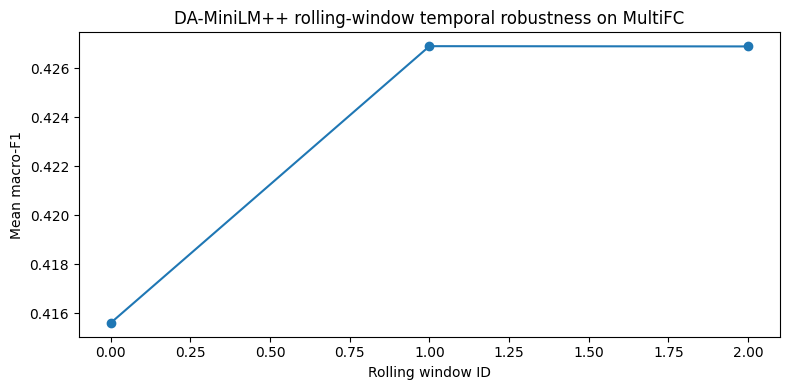

Saved: /kaggle/working/multifc_da_minilm_plus_v1_0/rolling_window_macro_f1.png


In [17]:
# ============================================================
# 13. Rolling-window temporal evaluation for DA-MiniLM++
# ============================================================

rolling_rows = []

if RUN_ROLLING_WINDOWS and RUN_DA_MINILM_PLUS and len(rolling_windows) > 0:
    ROLLING_TEXT_MODE = "claim_plus_safe_metadata"
    ROLLING_SEEDS = SEEDS
    X = all_embeddings[ROLLING_TEXT_MODE]

    for w in rolling_windows:
        for seed in ROLLING_SEEDS:
            print(f"\n[Rolling DA-MiniLM++] window={w['window_id']} seed={seed}")
            row, lambda_df, pred, proba = run_single_minilm_experiment(
                X, y_all, time_rank_all,
                w["train_idx"], w["valid_idx"], w["test_idx"],
                text_mode=ROLLING_TEXT_MODE,
                eval_setup="rolling_window",
                seed=seed,
                model_kind="da_minilm_mlp",
            )
            row.update({
                "window_id": w["window_id"],
                "train_end_frac": w["train_end_frac"],
                "valid_end_frac": w["valid_end_frac"],
                "test_end_frac": w["test_end_frac"],
            })
            rolling_rows.append(row)
            print(f"  macro_f1={row['macro_f1']:.4f}, acc={row['accuracy']:.4f}, lambda={row['recency_lambda']}")

rolling_results_df = pd.DataFrame(rolling_rows)
rolling_path = OUTPUT_DIR / "rolling_window_da_minilm_plus_results.csv"
rolling_results_df.to_csv(rolling_path, index=False)
print("Saved:", rolling_path)

if len(rolling_results_df) > 0:
    rolling_summary_df = summarize_results(
        rolling_results_df,
        group_cols=["window_id", "model", "text_mode", "eval_setup"]
    )
    rolling_summary_path = OUTPUT_DIR / "rolling_window_da_minilm_plus_summary.csv"
    rolling_summary_df.to_csv(rolling_summary_path, index=False)
    print("Saved:", rolling_summary_path)
    display(rolling_summary_df)

    plt.figure(figsize=(8, 4))
    plot_df = rolling_summary_df.sort_values("window_id")
    plt.plot(plot_df["window_id"], plot_df["macro_f1_mean"], marker="o")
    plt.xlabel("Rolling window ID")
    plt.ylabel("Mean macro-F1")
    plt.title("DA-MiniLM++ rolling-window temporal robustness on MultiFC")
    plt.tight_layout()
    fig_path = OUTPUT_DIR / "rolling_window_macro_f1.png"
    plt.savefig(fig_path, dpi=300)
    plt.show()
    print("Saved:", fig_path)
else:
    print("No rolling-window results generated.")

In [18]:
# ============================================================
# 14. Official unlabelled test.tsv predictions
# ============================================================

# This cell trains DA-MiniLM++ on the labelled train+dev data with an inner validation split,
# then predicts labels for the official unlabelled test.tsv.
# It is for generating submission/prediction files only, not for reporting test performance.

if RUN_OFFICIAL_TEST_PREDICTIONS and len(test_unlabelled) > 0 and RUN_DA_MINILM_PLUS:
    FINAL_TEXT_MODE = "claim_plus_safe_metadata"
    X_labelled = all_embeddings[FINAL_TEXT_MODE]
    X_official_test = test_embeddings[FINAL_TEXT_MODE]

    # Inner chronological split from labelled_all for lambda/calibration selection.
    ordered = labelled_all.sort_values("time_rank").index.to_numpy()
    cut = int(0.85 * len(ordered))
    final_train_idx = ordered[:cut]
    final_valid_idx = ordered[cut:]

    final_prediction_frames = []
    for seed in SEEDS:
        X_train = X_labelled[final_train_idx]
        y_train = y_all[final_train_idx]
        t_train = time_rank_all[final_train_idx]
        X_valid = X_labelled[final_valid_idx]
        y_valid = y_all[final_valid_idx]

        best = None
        payload = None
        for rec_lam in RECENCY_LAMBDAS:
            w_train = combined_sample_weights(y_train, t_train, recency_lambda=rec_lam)
            valid_proba, test_proba, raw_valid_f1 = train_da_minilm_mlp(
                X_train, y_train, w_train, X_valid, y_valid, X_official_test, seed=seed
            )
            calib = select_best_calibration(valid_proba, y_valid, y_train, objective="macro_f1")
            valid_cal = apply_bias_and_temperature(
                valid_proba,
                bias=logit_adjustment_bias(y_train, tau=calib["tau"]),
                temperature=calib["temperature"],
            )
            valid_pred = valid_cal.argmax(axis=1)
            valid_macro_f1 = f1_score(y_valid, valid_pred, average="macro", zero_division=0)
            if best is None or valid_macro_f1 > best["valid_macro_f1"]:
                best = {"seed": seed, "recency_lambda": rec_lam, "valid_macro_f1": float(valid_macro_f1), **calib}
                payload = test_proba

        test_cal = apply_bias_and_temperature(
            payload,
            bias=logit_adjustment_bias(y_train, tau=best["tau"]),
            temperature=best["temperature"],
        )
        pred_id = test_cal.argmax(axis=1)
        pred_label = [id_to_label[int(i)] for i in pred_id]

        pred_df = test_unlabelled[["claim_id", "claim", "source_site", "category", "speaker"]].copy()
        pred_df["seed"] = seed
        pred_df["pred_label"] = pred_label
        pred_df["pred_id"] = pred_id
        for i, lab in id_to_label.items():
            pred_df[f"proba_{lab}"] = test_cal[:, i]
        pred_df["selected_recency_lambda"] = best["recency_lambda"]
        pred_df["selected_tau"] = best["tau"]
        pred_df["selected_temperature"] = best["temperature"]
        pred_df["inner_valid_macro_f1"] = best["valid_macro_f1"]
        final_prediction_frames.append(pred_df)

    all_seed_pred_df = pd.concat(final_prediction_frames, ignore_index=True)
    all_seed_path = OUTPUT_DIR / "official_test_predictions_all_seeds.csv"
    all_seed_pred_df.to_csv(all_seed_path, index=False)
    print("Saved:", all_seed_path)

    # Majority vote / mean probability ensemble across seeds.
    proba_cols = [f"proba_{lab}" for lab in LABEL_ORDER]
    ensemble = (
        all_seed_pred_df.groupby(["claim_id", "claim", "source_site", "category", "speaker"], dropna=False)[proba_cols]
        .mean()
        .reset_index()
    )
    ensemble_proba = ensemble[proba_cols].values
    ensemble["pred_id"] = ensemble_proba.argmax(axis=1)
    ensemble["pred_label"] = [id_to_label[int(i)] for i in ensemble["pred_id"]]
    ensemble_path = OUTPUT_DIR / "official_test_predictions_seed_ensemble.csv"
    ensemble.to_csv(ensemble_path, index=False)
    print("Saved:", ensemble_path)
    display(ensemble.head())
else:
    print("Official test predictions skipped.")

Saved: /kaggle/working/multifc_da_minilm_plus_v1_0/official_test_predictions_all_seeds.csv
Saved: /kaggle/working/multifc_da_minilm_plus_v1_0/official_test_predictions_seed_ensemble.csv


,claim_id,claim,source_site,category,speaker,proba_false,proba_mixed,proba_true,pred_id,pred_label
0,abbc-00001,Protestors have marched through the streets of...,abbc,"['abortion', 'liberals', 'law-crime-and-justic...",,0.247761,0.586431,0.165808,1,mixed
1,abbc-00017,"From mid-September, Australians will begin rec...",abbc,"['gays-and-lesbians', 'marriage', 'alp', 'aust...",,0.181377,0.623309,0.195314,1,mixed
2,abbc-00020,"An award provides ""pay rates and conditions of...",abbc,"['alp', 'industrial-relations', 'australia']",,0.184103,0.421229,0.394667,1,mixed
3,abbc-00048,The claim: Deputy Liberal Leader Julie Bishop ...,abbc,"['government-and-politics', 'liberals', 'austr...",,0.276963,0.345108,0.377929,2,true
4,abbc-00056,The claim: Peter Dutton says the Federal Gover...,abbc,"['diseases-and-disorders', 'health', 'world-po...",,0.206213,0.580858,0.212929,1,mixed


In [19]:
# ============================================================
# 15. Final report export and zip
# ============================================================

summary_lines = []
summary_lines.append("MultiFC DA-MiniLM++ Temporal Robustness Experiment")
summary_lines.append("=" * 80)
summary_lines.append("")
summary_lines.append("Main model:")
summary_lines.append("DA-MiniLM++ = frozen MiniLM embeddings + class-balanced weighting + recency weighting + validation calibration.")
summary_lines.append("")
summary_lines.append("Dataset note:")
summary_lines.append("MultiFC labels are harmonized into a transparent 3-class veracity space: false, mixed, true.")
summary_lines.append("Evidence text and fact-check article titles are excluded by default to reduce leakage risk.")
summary_lines.append("")
summary_lines.append("Evaluation protocols:")
summary_lines.append("1. official_train_to_dev: inner validation from train only; dev is held out for evaluation.")
summary_lines.append("2. internal_chronological: 70/15/15 chronological split on train+dev labelled rows.")
summary_lines.append("3. internal_random_stratified: 70/15/15 random stratified split on train+dev labelled rows.")
summary_lines.append("4. rolling_window: expanding temporal windows for DA-MiniLM++.")
summary_lines.append("")
summary_lines.append("Files exported:")
for p in sorted(OUTPUT_DIR.glob("*.csv")):
    summary_lines.append(f"- {p.name}")

if "summary_df" in globals() and len(summary_df) > 0:
    summary_lines.append("")
    summary_lines.append("Main mean/std summary:")
    summary_lines.append("-" * 80)
    summary_lines.append(summary_df.to_string(index=False))

if "bootstrap_df" in globals() and len(bootstrap_df) > 0:
    summary_lines.append("")
    summary_lines.append("Bootstrap tests with BH correction:")
    summary_lines.append("-" * 80)
    summary_lines.append(bootstrap_df.to_string(index=False))

if "rolling_summary_df" in globals() and len(rolling_summary_df) > 0:
    summary_lines.append("")
    summary_lines.append("Rolling-window summary:")
    summary_lines.append("-" * 80)
    summary_lines.append(rolling_summary_df.to_string(index=False))

summary_text = "\n".join(summary_lines)
summary_path = OUTPUT_DIR / "experiment_summary.txt"
with open(summary_path, "w", encoding="utf-8") as f:
    f.write(summary_text)

print(summary_text)

zip_path = shutil.make_archive(str(OUTPUT_DIR), "zip", OUTPUT_DIR)
print("Created zip:", zip_path)

MultiFC DA-MiniLM++ Temporal Robustness Experiment

Main model:
DA-MiniLM++ = frozen MiniLM embeddings + class-balanced weighting + recency weighting + validation calibration.

Dataset note:
MultiFC labels are harmonized into a transparent 3-class veracity space: false, mixed, true.
Evidence text and fact-check article titles are excluded by default to reduce leakage risk.

Evaluation protocols:
1. official_train_to_dev: inner validation from train only; dev is held out for evaluation.
2. internal_chronological: 70/15/15 chronological split on train+dev labelled rows.
3. internal_random_stratified: 70/15/15 random stratified split on train+dev labelled rows.
4. rolling_window: expanding temporal windows for DA-MiniLM++.

Files exported:
- confusion_matrix_DA-MiniLM__claim_only_official_seed42.csv
- confusion_matrix_DA-MiniLM__claim_plus_safe_metadata_official_seed42.csv
- confusion_matrix_MiniLM-LogReg-RW_claim_only_official_seed42.csv
- confusion_matrix_MiniLM-LogReg-RW_claim_plus_saf